# Question 1: Rwanda Maize Yield Dataset Preparation

## Objective
Inspect, clean, preprocess, and document the provided maize yield dataset to make it suitable for future machine learning.

## Dataset
Expected filename: `maize_yield_rwanda_raw.csv`

## Data provenance
Source: Lecturer-provided dataset.
Status: Awaiting receipt.

## Planned workflow
1. Load and inspect the raw dataset.
2. Examine data types and descriptive statistics.
3. Identify missing values and duplicates.
4. Investigate invalid values and outliers.
5. Apply justified cleaning and preprocessing.
6. Visualize key patterns.
7. Export the processed dataset.

No data will be fabricated or altered without documentation.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Question 1 notebook initialized successfully!")


Question 1 notebook initialized successfully!


In [4]:
# Step 1 — Load the dataset in Jupyter
data_path = Path("../data/raw/maize_yield_rwanda_rw.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())



Dataset shape: (1426, 20)

Column names:
['record_id', 'year', 'season', 'province', 'district', 'altitude_m', 'rainfall_mm', 'avg_temp_c', 'soil_ph', 'soil_type', 'seed_variety', 'farming_practice', 'npk_kg_ha', 'urea_kg_ha', 'manure_t_ha', 'plant_density_per_ha', 'farm_area_ha', 'irrigation', 'pest_incidence_index', 'yield_t_ha']


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


In [21]:
# Step 2 — Inspect missing values in Jupyter

# Count missing values in every column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing cells:", missing_values.sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values by column:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64

Total missing cells: 39
Duplicate rows: 0


In [6]:

# Count missing values in every column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing cells:", missing_values.sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values by column:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64

Total missing cells: 39
Duplicate rows: 0


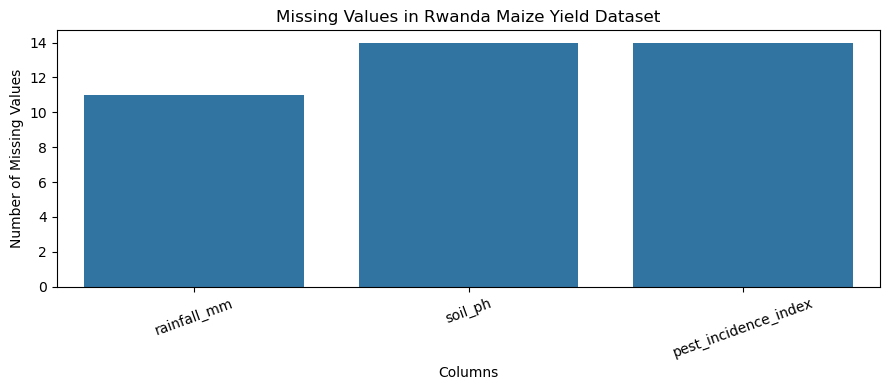

In [7]:
# Step 3 — Visualize the missing values
import matplotlib.pyplot as plt
import seaborn as sns

missing = df.isnull().sum()
missing = missing[missing > 0]

plt.figure(figsize=(9, 4))
sns.barplot(x=missing.index, y=missing.values)

plt.title("Missing Values in Rwanda Maize Yield Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [8]:

# Keep the original data unchanged
df_clean = df.copy()

# Remove exact duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Fill missing numerical values using the median
columns_to_fill = [
    "rainfall_mm",
    "soil_ph",
    "pest_incidence_index"
]

for col in columns_to_fill:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

    print(f"{col}: filled missing values with median {median_value:.3f}")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)


rainfall_mm: filled missing values with median 530.600
soil_ph: filled missing values with median 5.840
pest_incidence_index: filled missing values with median 0.261

Missing values after cleaning:
record_id               0
year                    0
season                  0
province                0
district                0
altitude_m              0
rainfall_mm             0
avg_temp_c              0
soil_ph                 0
soil_type               0
seed_variety            0
farming_practice        0
npk_kg_ha               0
urea_kg_ha              0
manure_t_ha             0
plant_density_per_ha    0
farm_area_ha            0
irrigation              0
pest_incidence_index    0
yield_t_ha              0
dtype: int64

Cleaned dataset shape: (1426, 20)


In [9]:

# Basic validity checks
checks = {
    "negative_rainfall": (df_clean["rainfall_mm"] < 0).sum(),
    "invalid_soil_ph": (
        (df_clean["soil_ph"] < 0) |
        (df_clean["soil_ph"] > 14)
    ).sum(),
    "negative_fertilizer": (
        (df_clean["npk_kg_ha"] < 0) |
        (df_clean["urea_kg_ha"] < 0)
    ).sum(),
    "nonpositive_farm_area": (
        df_clean["farm_area_ha"] <= 0
    ).sum(),
    "negative_yield": (
        df_clean["yield_t_ha"] < 0
    ).sum()
}

for name, count in checks.items():
    print(f"{name}: {count}")


negative_rainfall: 0
invalid_soil_ph: 0
negative_fertilizer: 0
nonpositive_farm_area: 0
negative_yield: 0


In [10]:

from pathlib import Path

output_path = Path("../data/processed/maize_yield_rwanda_clean.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))


Cleaned dataset saved to: ../data/processed/maize_yield_rwanda_clean.csv
Rows: 1426
Columns: 20


In [11]:

# Select numeric columns
numeric_cols = df_clean.select_dtypes(
    include="number"
).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_summary.append({
        "column": col,
        "outliers": int(count),
        "lower_bound": lower,
        "upper_bound": upper
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.sort_values("outliers", ascending=False))


,column,outliers,lower_bound,upper_bound
9,farm_area_ha,75,-0.32000,1.76000
10,pest_incidence_index,13,-0.19250,0.73150
4,soil_ph,11,4.67000,6.99000
11,yield_t_ha,8,0.59000,4.51000
7,manure_t_ha,6,-1.89125,5.97875
2,rainfall_mm,0,114.77500,933.77500
1,altitude_m,0,947.87500,2438.87500
0,year,0,2009.50000,2029.50000
3,avg_temp_c,0,14.01250,24.71250
5,npk_kg_ha,0,-91.71250,222.98750


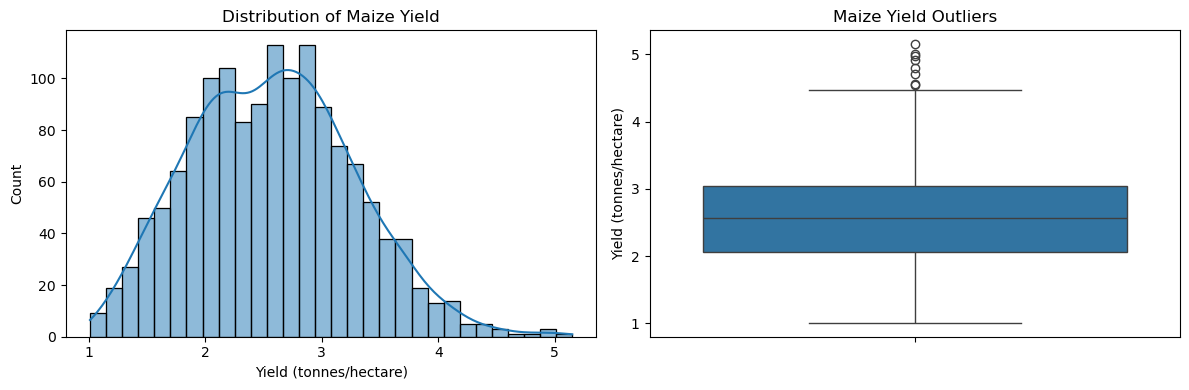

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df_clean["yield_t_ha"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Maize Yield")
axes[0].set_xlabel("Yield (tonnes/hectare)")

sns.boxplot(
    y=df_clean["yield_t_ha"],
    ax=axes[1]
)
axes[1].set_title("Maize Yield Outliers")
axes[1].set_ylabel("Yield (tonnes/hectare)")

plt.tight_layout()
plt.show()


In [13]:

# Separate features from the target
X = df.copy().drop(columns=[
    "record_id",
    "yield_t_ha"
])

y = df["yield_t_ha"].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical columns:")
print(X.select_dtypes(
    include=["object", "category"]
).columns.tolist())

print("\nNumeric columns:")
print(X.select_dtypes(
    include="number"
).columns.tolist())



Input shape: (1426, 18)
Target shape: (1426,)

Categorical columns:
['season', 'province', 'district', 'soil_type', 'seed_variety', 'farming_practice', 'irrigation']

Numeric columns:
['year', 'altitude_m', 'rainfall_mm', 'avg_temp_c', 'soil_ph', 'npk_kg_ha', 'urea_kg_ha', 'manure_t_ha', 'plant_density_per_ha', 'farm_area_ha', 'pest_incidence_index']


In [14]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1140
Testing records: 286


In [15]:
# 80/20 training/testing split.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1140
Testing records: 286


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Learn preprocessing rules from training data only
X_train_ready = preprocessor.fit_transform(X_train)

# Apply the same rules to testing data
X_test_ready = preprocessor.transform(X_test)

print("Training shape:", X_train_ready.shape)
print("Testing shape:", X_test_ready.shape)


Training shape: (1140, 64)
Testing shape: (286, 64)


In [17]:

feature_names = preprocessor.get_feature_names_out()

train_ready_df = pd.DataFrame(
    X_train_ready,
    columns=feature_names,
    index=X_train.index
)

test_ready_df = pd.DataFrame(
    X_test_ready,
    columns=feature_names,
    index=X_test.index
)

# Attach the target to each dataset
train_ready_df["yield_t_ha"] = y_train
test_ready_df["yield_t_ha"] = y_test

print("Training dataset:")
display(train_ready_df.head())

print("Missing values in training data:",
      train_ready_df.isna().sum().sum())

print("Missing values in testing data:",
      test_ready_df.isna().sum().sum())


Training dataset:


,numeric__year,numeric__altitude_m,numeric__rainfall_mm,numeric__avg_temp_c,numeric__soil_ph,numeric__npk_kg_ha,numeric__urea_kg_ha,numeric__manure_t_ha,numeric__plant_density_per_ha,numeric__farm_area_ha,...,categorical__seed_variety_PAN691,categorical__seed_variety_RHM104,categorical__seed_variety_WH505,categorical__seed_variety_ZM607,categorical__seed_variety_ZM621,categorical__farming_practice_Improved,categorical__farming_practice_Traditional,categorical__irrigation_No,categorical__irrigation_Yes,yield_t_ha
306,-0.868157,0.603249,1.988910,-1.357220,-0.022114,0.284293,1.201039,2.013674,0.986420,0.282050,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,4.98
1139,0.881046,0.089856,-0.939017,-0.385379,-0.930576,0.570537,1.408979,0.917751,0.605566,-0.573360,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.09
31,-1.567838,-0.729772,-0.306616,1.497561,-0.112960,-0.538394,-0.977535,0.584531,-1.687793,1.098577,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,2.39
210,-1.217997,1.094125,-0.316315,-1.175000,-1.293961,-0.695298,-1.105498,-1.533266,-0.784284,-0.223419,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,2.17
924,0.531205,-1.927689,-0.391971,1.558301,0.795502,0.248248,-0.129779,0.192072,-1.689827,1.156900,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,2.66


Missing values in training data: 0
Missing values in testing data: 0


In [18]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_ready_df.to_csv(
    output_dir / "maize_train_ml_ready.csv",
    index=False
)

test_ready_df.to_csv(
    output_dir / "maize_test_ml_ready.csv",
    index=False
)

print("ML-ready training and testing datasets saved!")


ML-ready training and testing datasets saved!


In [19]:

import joblib

joblib.dump(
    preprocessor,
    output_dir / "maize_preprocessor.joblib"
)

print("Preprocessing pipeline saved!")


Preprocessing pipeline saved!
